FLIGHT FARE PREDICTION PROJECT
IMPORT LIBRARIES
LOAD DATASET
Dataset Loaded Successfully

================ DATASET INFORMATION ================
       Airline Date_of_Journey    Source Destination                  Route  \
0       IndiGo      24/03/2019  Banglore   New Delhi              BLR → DEL   
1    Air India       1/05/2019   Kolkata    Banglore  CCU → IXR → BBI → BLR   
2  Jet Airways       9/06/2019     Delhi      Cochin  DEL → LKO → BOM → COK   
3       IndiGo      12/05/2019   Kolkata    Banglore        CCU → NAG → BLR   
4       IndiGo      01/03/2019  Banglore   New Delhi        BLR → NAG → DEL   

  Dep_Time  Arrival_Time Duration Total_Stops Additional_Info  Price  
0    22:20  01:10 22 Mar   2h 50m    non-stop         No info   3897  
1    05:50         13:15   7h 25m     2 stops         No info   7662  
2    09:25  04:25 10 Jun      19h     2 stops         No info  13882  
3    18:05         23:30   5h 25m      1 stop         No info   6218  
4    16:50         21:35  

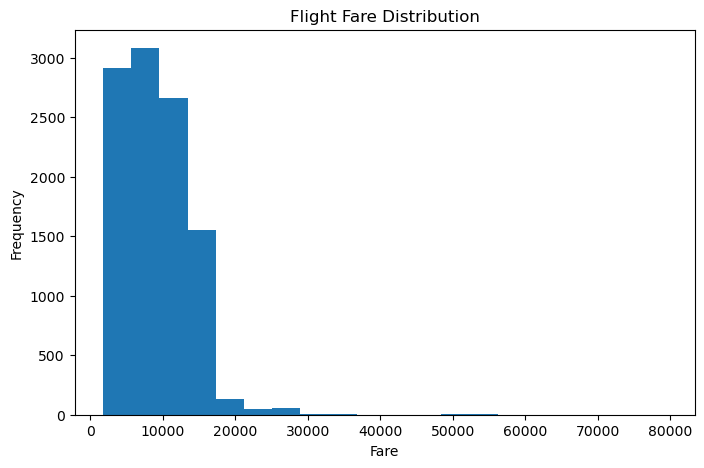


================ LABEL ENCODING ================
Airline Encoded Successfully
Date_of_Journey Encoded Successfully
Source Encoded Successfully
Destination Encoded Successfully
Route Encoded Successfully
Dep_Time Encoded Successfully
Arrival_Time Encoded Successfully
Duration Encoded Successfully
Total_Stops Encoded Successfully
Additional_Info Encoded Successfully

Encoded Dataset:
   Airline  Date_of_Journey  Source  Destination  Route  Dep_Time  \
0        3               24       0            5     18       211   
1        1                6       3            0     84        31   
2        4               43       2            1    118        70   
3        3               10       3            0     91       164   
4        3                0       0            5     29       149   

   Arrival_Time  Duration  Total_Stops  Additional_Info  Price  
0           233       240            4                8   3897  
1           906       336            1                8   7662  
2   

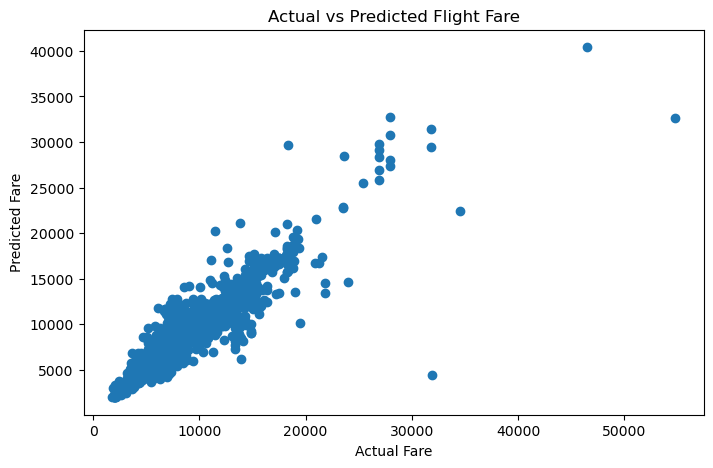


================ FEATURE IMPORTANCE ================
           Feature  Importance
8      Total_Stops    0.418402
1  Date_of_Journey    0.186402
0          Airline    0.162463
4            Route    0.053607
6     Arrival_Time    0.046644
7         Duration    0.045855
5         Dep_Time    0.035665
9  Additional_Info    0.034783
2           Source    0.010029
3      Destination    0.006151


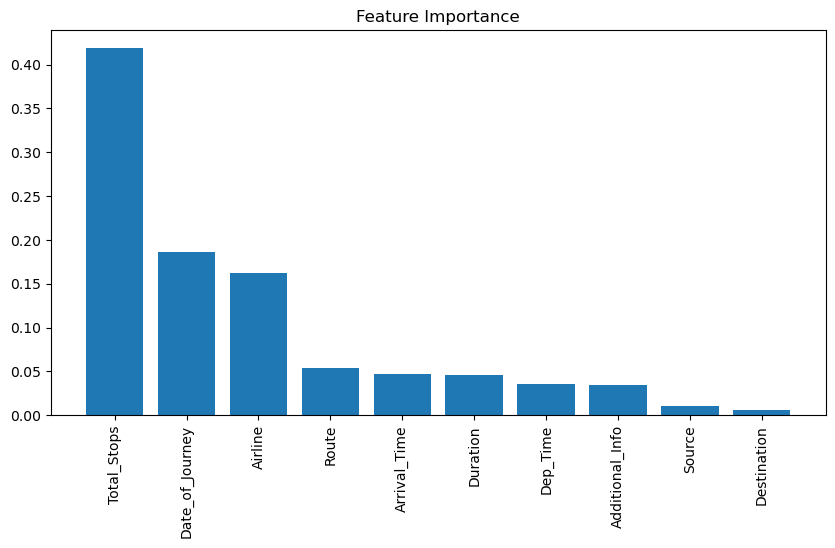


================ SAMPLE PREDICTIONS ================
   Actual Fare  Predicted Fare
0        15894        13796.88
1         8366        10841.16
2         3943         3974.76
3         8085         8725.99
4         4049         5319.34
5         4668         4905.65
6        11411        12411.23
7         7594         7704.69
8         7934         7516.95
9        12692        12874.16

================ SAVE MODEL OUTPUT ================
Prediction File Saved Successfully
File Name: Flight_Fare_Predictions.csv

================ PROJECT SUMMARY ================
1. Dataset Loaded Successfully
2. Data Cleaning Completed
3. Exploratory Data Analysis Completed
4. Label Encoding Applied
5. Random Forest Model Trained
6. Flight Fare Prediction Completed
7. Model Evaluation Completed
8. Results Saved Successfully

================ CHALLENGES FACED ================
1. Handling missing values in dataset
2. Encoding categorical features correctly
3. Managing duplicate records
4. Selecting s

In [4]:
print("FLIGHT FARE PREDICTION PROJECT")

print("IMPORT LIBRARIES")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("LOAD DATASET")

file_path = 'Flight_Fare.xlsx'

try:
    df = pd.read_excel(file_path)
    print('Dataset Loaded Successfully')
except:
    print('File not found. Please upload Flight_Fare.xlsx')

print("\n================ DATASET INFORMATION ================")

print(df.head())

print('\nDataset Shape:', df.shape)

print('\nColumns in Dataset:')
print(df.columns)

print('\nMissing Values:')
print(df.isnull().sum())

print('\nDataset Description:')
print(df.describe(include='all'))

print("\n================ DATA CLEANING ================")

before = df.shape[0]

df.drop_duplicates(inplace=True)

after = df.shape[0]

print('Duplicate Rows Removed:', before - after)

for col in df.columns:
    if df[col].dtype == 'object':
        df[col].fillna(df[col].mode()[0], inplace=True)
    else:
        df[col].fillna(df[col].mean(), inplace=True)

print('\nMissing Values After Cleaning:')
print(df.isnull().sum())

print("\n================ EXPLORATORY DATA ANALYSIS ================")

plt.figure(figsize=(8,5))
plt.hist(df.iloc[:, -1], bins=20)

plt.title('Flight Fare Distribution')
plt.xlabel('Fare')
plt.ylabel('Frequency')

plt.show()

print("\n================ LABEL ENCODING ================")

label_encoder = LabelEncoder()

for col in df.columns:
    if df[col].dtype == 'object':
        df[col] = label_encoder.fit_transform(df[col].astype(str))
        print(col, 'Encoded Successfully')

print('\nEncoded Dataset:')
print(df.head())

print("\n================ DEFINE FEATURES AND TARGET ================")

X = df.iloc[:, :-1]
y = df.iloc[:, -1]

print('\nFeature Shape:', X.shape)
print('Target Shape:', y.shape)

print("\n================ TRAIN TEST SPLIT ================")

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print('\nTraining Data Shape:', X_train.shape)
print('Testing Data Shape:', X_test.shape)

print("\n================ MODEL TRAINING ================")

model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print('Random Forest Model Trained Successfully')

print("\n================ PREDICTION ================")

y_pred = model.predict(X_test)

print('\nPredictions Completed')

print("\n================ MODEL EVALUATION ================")

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print('Mean Absolute Error :', mae)
print('Mean Squared Error  :', mse)
print('Root Mean Squared Error :', rmse)
print('R2 Score :', r2)

print("\n================ ACTUAL VS PREDICTED PLOT ================")

plt.figure(figsize=(8,5))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Fare')
plt.ylabel('Predicted Fare')

plt.title('Actual vs Predicted Flight Fare')

plt.show()

print("\n================ FEATURE IMPORTANCE ================")

importance = model.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

plt.figure(figsize=(10,5))

plt.bar(
    feature_importance['Feature'],
    feature_importance['Importance']
)

plt.xticks(rotation=90)

plt.title('Feature Importance')

plt.show()

print("\n================ SAMPLE PREDICTIONS ================")

results = pd.DataFrame({
    'Actual Fare': y_test.values,
    'Predicted Fare': y_pred
})

print(results.head(10))

print("\n================ SAVE MODEL OUTPUT ================")

results.to_csv(
    'Flight_Fare_Predictions.csv',
    index=False
)

print('Prediction File Saved Successfully')

print('File Name: Flight_Fare_Predictions.csv')

print("\n================ PROJECT SUMMARY ================")

print('1. Dataset Loaded Successfully')
print('2. Data Cleaning Completed')
print('3. Exploratory Data Analysis Completed')
print('4. Label Encoding Applied')
print('5. Random Forest Model Trained')
print('6. Flight Fare Prediction Completed')
print('7. Model Evaluation Completed')
print('8. Results Saved Successfully')

print("\n================ CHALLENGES FACED ================")

challenges = [
    'Handling missing values in dataset',
    'Encoding categorical features correctly',
    'Managing duplicate records',
    'Selecting suitable machine learning algorithm',
    'Improving prediction accuracy',
    'Handling outliers in flight fare data',
    'Understanding feature importance',
    'Splitting data for training and testing properly',
    'Reducing model overfitting',
    'Visualizing large dataset information'
]

for i, challenge in enumerate(challenges, start=1):
    print(str(i) + '.', challenge)

print("\n================ TECHNIQUES USED ================")

techniques = [
    'Data Cleaning',
    'Handling Missing Values',
    'Label Encoding',
    'Exploratory Data Analysis',
    'Train Test Split',
    'Random Forest Regression',
    'Model Evaluation Metrics',
    'Feature Importance Analysis',
    'Data Visualization'
]

for i, technique in enumerate(techniques, start=1):
    print(str(i) + '.', technique)

print("\n================ CONCLUSION ================")

print('The Flight Fare Prediction project successfully predicts flight ticket prices using machine learning techniques.')

print('Random Forest Regressor provided good prediction accuracy and handled dataset complexity effectively.')

print('The project demonstrates how data preprocessing, visualization, and machine learning can solve real-world problems.')

print("\n================ END OF PROJECT ================")